In [1]:
import pandas as pd
import matplotlib.pyplot as plt

data_path = "../data/mlcasestudy.csv"
df = pd.read_csv(data_path)

In [2]:
df.head()

,loan_id,loan_issue_date,loan_amount,amount_outstanding_14d,amount_outstanding_21d,card_expiry_month,card_expiry_year,existing_debt,num_active_loans,days_since_first_loan,...,num_failed_payments_3m,num_failed_payments_6m,num_failed_payments_1y,amount_repaid_14d,amount_repaid_1m,amount_repaid_3m,amount_repaid_6m,amount_repaid_1y,merchant_group,merchant_category
0,a55cf3062bd45a83766096fd0c4697d6,2023-06-24,5300,0,0,2.0,2026.0,21098.0,2,717,...,0,0,0,6875,15580,42325,67878,152193,Clothing & Shoes,Adult Shoes & Clothing
1,45e3d15cb313d767470722e952e14313,2023-09-22,9547,7161,7161,6.0,2027.0,NaN,0,-1,...,0,0,0,0,0,0,0,0,"Leisure, Sport & Hobby",Concept Stores & Miscellaneous
2,b195c127c7605b7b936b90bcdb5e889c,2023-07-03,5948,0,0,12.0,2023.0,NaN,0,-1,...,0,0,0,0,0,0,0,0,Clothing & Shoes,General Shoes & Clothing
3,36028b1dbeb4aeef565a79ca9700667a,2023-08-19,15871,11904,0,2.0,2026.0,31742.0,1,0,...,0,0,0,0,0,0,0,0,Clothing & Shoes,Youthful Shoes & Clothing
4,5317f8e22a8f790b6e11a0f12320422d,2023-09-30,19510,0,0,8.0,2026.0,9064.0,1,501,...,0,0,0,6511,14000,32289,61993,116532,"Leisure, Sport & Hobby",Sports Gear & Outdoor


In [3]:
df['loan_issue_date'].min(), df['loan_issue_date'].max()

('2023-06-01', '2023-10-27')

In [4]:
len(df)

111902

In [5]:
df['merchant_group'].value_counts()

merchant_group
Clothing & Shoes          64623
Intangible products       15728
Leisure, Sport & Hobby     9397
Jewelry & Accessories      8067
Home & Garden              4090
Health & Beauty            3680
Electronics                2193
Food & Beverage            2088
Unknown                    1284
Children Products           327
Erotic Materials            249
Automotive Products         134
Entertainment                42
Name: count, dtype: int64

In [6]:
## Too many categories: it probably makes sense to break down the biggest groups such as Clothing & Shoes as future developments
df['merchant_category'].value_counts()

merchant_category
General Shoes & Clothing             37875
Youthful Shoes & Clothing            17621
Adult Shoes & Clothing                9072
Event - Broker & Agencies             6499
Travel - Accommodation & Resorts      6314
                                     ...  
Video Games & Related Accessories        3
Costumes & Party Supplies                3
Cleaning & Sanitary                      3
Music & Movies                           1
Erotic Clothing & Accessories            1
Name: count, Length: 63, dtype: int64

In [7]:
## Create target variable: If we want to predict the probability of default (i.e. the debt has not been paid after 21 days), the target will be:
df['default_flag'] = df['amount_outstanding_21d'] > 0
df['default_flag'].value_counts() / len(df)
## Default rate is 5.44%

default_flag
False    0.945586
True     0.054414
Name: count, dtype: float64

In [8]:
## Remove NaN from existing_debt and create flag
df['existing_debt'] = df['existing_debt'].fillna(0)
df['existing_debt_flag'] = df['existing_debt'] > 0

In [9]:
df['existing_debt_flag'].value_counts() / len(df)

existing_debt_flag
False    0.624582
True     0.375418
Name: count, dtype: float64

In [10]:
df = pd.get_dummies(df, columns=['merchant_group'])
df.head()

,loan_id,loan_issue_date,loan_amount,amount_outstanding_14d,amount_outstanding_21d,card_expiry_month,card_expiry_year,existing_debt,num_active_loans,days_since_first_loan,...,merchant_group_Electronics,merchant_group_Entertainment,merchant_group_Erotic Materials,merchant_group_Food & Beverage,merchant_group_Health & Beauty,merchant_group_Home & Garden,merchant_group_Intangible products,merchant_group_Jewelry & Accessories,"merchant_group_Leisure, Sport & Hobby",merchant_group_Unknown
0,a55cf3062bd45a83766096fd0c4697d6,2023-06-24,5300,0,0,2.0,2026.0,21098.0,2,717,...,False,False,False,False,False,False,False,False,False,False
1,45e3d15cb313d767470722e952e14313,2023-09-22,9547,7161,7161,6.0,2027.0,0.0,0,-1,...,False,False,False,False,False,False,False,False,True,False
2,b195c127c7605b7b936b90bcdb5e889c,2023-07-03,5948,0,0,12.0,2023.0,0.0,0,-1,...,False,False,False,False,False,False,False,False,False,False
3,36028b1dbeb4aeef565a79ca9700667a,2023-08-19,15871,11904,0,2.0,2026.0,31742.0,1,0,...,False,False,False,False,False,False,False,False,False,False
4,5317f8e22a8f790b6e11a0f12320422d,2023-09-30,19510,0,0,8.0,2026.0,9064.0,1,501,...,False,False,False,False,False,False,False,False,True,False


In [11]:
df.columns

Index(['loan_id', 'loan_issue_date', 'loan_amount', 'amount_outstanding_14d',
       'amount_outstanding_21d', 'card_expiry_month', 'card_expiry_year',
       'existing_debt', 'num_active_loans', 'days_since_first_loan',
       'new_exposure_7d', 'new_exposure_14d', 'num_confirmed_payments_3m',
       'num_confirmed_payments_6m', 'num_failed_payments_3m',
       'num_failed_payments_6m', 'num_failed_payments_1y', 'amount_repaid_14d',
       'amount_repaid_1m', 'amount_repaid_3m', 'amount_repaid_6m',
       'amount_repaid_1y', 'merchant_category', 'default_flag',
       'existing_debt_flag', 'merchant_group_Automotive Products',
       'merchant_group_Children Products', 'merchant_group_Clothing & Shoes',
       'merchant_group_Electronics', 'merchant_group_Entertainment',
       'merchant_group_Erotic Materials', 'merchant_group_Food & Beverage',
       'merchant_group_Health & Beauty', 'merchant_group_Home & Garden',
       'merchant_group_Intangible products',
       'merchant_group_

Text(0, 0.5, 'Amount repaid 6m')

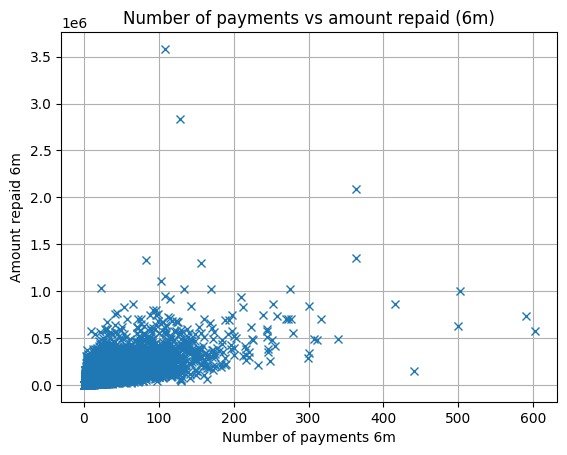

In [12]:
plt.figure()
plt.title('Number of payments vs amount repaid (6m)')
plt.plot(df['num_confirmed_payments_6m'], df['amount_repaid_6m'], 'x')
plt.grid()
plt.xlabel('Number of payments 6m')
plt.ylabel('Amount repaid 6m')

In [13]:
possible_features = [
    'loan_amount',
    'existing_debt',
    'existing_debt_flag',
    'num_active_loans',
    'days_since_first_loan',
    'new_exposure_7d', 'new_exposure_14d', 'num_confirmed_payments_3m',
    'num_confirmed_payments_6m', 'num_failed_payments_3m',
    'num_failed_payments_6m', 'num_failed_payments_1y', 'amount_repaid_14d',
    'amount_repaid_1m', 'amount_repaid_3m', 'amount_repaid_6m',
    'amount_repaid_1y'
] + [col for col in df.columns if col.startswith('merchant_group')]
## can't use amount_outstanding_14d because we want to predict before the loan is issued

In [14]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df[possible_features], df['default_flag'], test_size=0.2, random_state=42)

In [26]:
from sklearn.feature_selection import SelectKBest, f_classif, f_regression
selector = SelectKBest(score_func=f_classif, k='all')
selector.fit_transform(X_train, y_train)
for feature, score in zip(possible_features, selector.scores_):
    print(feature, score)

loan_amount 6.316406181446788
existing_debt 36.544665899877046
existing_debt_flag 76.91360176081744
num_active_loans 63.757564317606935
days_since_first_loan 254.9707866209805
new_exposure_7d 0.2804015036924651
new_exposure_14d 6.69118740375874
num_confirmed_payments_3m 182.9528948218768
num_confirmed_payments_6m 210.31681858132558
num_failed_payments_3m 13.394680983085983
num_failed_payments_6m 75.45828678784144
num_failed_payments_1y 159.29652381186204
amount_repaid_14d 68.47428528623655
amount_repaid_1m 101.15194536652916
amount_repaid_3m 163.84061987613723
amount_repaid_6m 183.66804754538612
amount_repaid_1y 204.8312863128229
merchant_group_Automotive Products 0.054672253085589644
merchant_group_Children Products 0.691065941226178
merchant_group_Clothing & Shoes 44.26470448098124
merchant_group_Electronics 3.0746631210278466
merchant_group_Entertainment 0.40623733718895993
merchant_group_Erotic Materials 0.8357339169839918
merchant_group_Food & Beverage 18.532183752862984
merchant_

In [27]:
selector = SelectKBest(score_func=f_regression, k='all')
selector.fit_transform(X_train, y_train)
for feature, score in zip(possible_features, selector.scores_):
    print(feature, score)

loan_amount 6.316406181435671
existing_debt 36.544665899878886
existing_debt_flag 76.91360176081675
num_active_loans 63.75756431760844
days_since_first_loan 254.97078662099278
new_exposure_7d 0.28040150369145844
new_exposure_14d 6.691187403758264
num_confirmed_payments_3m 182.95289482188394
num_confirmed_payments_6m 210.31681858133754
num_failed_payments_3m 13.394680983086495
num_failed_payments_6m 75.45828678784453
num_failed_payments_1y 159.29652381186875
amount_repaid_14d 68.47428528624278
amount_repaid_1m 101.15194536653169
amount_repaid_3m 163.84061987614515
amount_repaid_6m 183.6680475453953
amount_repaid_1y 204.8312863128294
merchant_group_Automotive Products 0.05467225308559238
merchant_group_Children Products 0.6910659412261612
merchant_group_Clothing & Shoes 44.2647044809936
merchant_group_Electronics 3.074663121028211
merchant_group_Entertainment 0.4062373371889771
merchant_group_Erotic Materials 0.8357339169840153
merchant_group_Food & Beverage 18.532183752863737
merchant_g

In [16]:
## Preliminary considerations:
# loan amount does not seem very relevant to predict default
# existence of debt seems more relevant than the amount of said debt
# long term behaviour (days_since_first_loan, num_confirmed_payments_3m/6m, num_failed_payments_6m/1y, amount_repaid_3m/6m/1y) seems more relevant than short term
# positive behaviour (confirmed payments) seems more relevant than negative behaviour (failed payments)
# these 2 considerations should be studied with the policies issued by the company
# some merchant categories seem relevant

In [18]:
proposed_features = [
    'existing_debt_flag',
    'num_active_loans',
    'days_since_first_loan',
    'num_confirmed_payments_3m',
    'num_confirmed_payments_6m',
    'num_failed_payments_6m',
    'num_failed_payments_1y',
    'merchant_group_Clothing & Shoes',
    'merchant_group_Jewelry & Accessories',
    'merchant_group_Leisure, Sport & Hobby'
]
'''
Models:
- Logistic Regression
- Decision Tree (Regression)
- Random Forest (Regression)
- XGBoost (Regression)
Performance metrics:
- AUC
- R2
- MSE
- MAE
'''

'\nModels:\n- Logistic Regression\n- Decision Tree (Regression)\n- Random Forest (Regression)\n- XGBoost (Regression)\nPerformance metrics:\n- AUC\n- R2\n- MSE\n'

In [19]:
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

logistic_regressor1 = make_pipeline(StandardScaler(), LogisticRegression(solver='lbfgs', penalty='l2', max_iter=1000)).fit(X_train[proposed_features], y_train)
logistic_regressor2 = make_pipeline(StandardScaler(), LogisticRegression(solver='liblinear', penalty='l1', max_iter=1000)).fit(X_train[proposed_features], y_train)
linear_regressor = LinearRegression().fit(X_train[proposed_features], y_train)
tree_regressor = DecisionTreeRegressor(max_depth=4, min_samples_leaf=50).fit(X_train[proposed_features], y_train)
forest_regressor = RandomForestRegressor().fit(X_train[proposed_features], y_train)
xgb_regressor = XGBRegressor().fit(X_train[proposed_features], y_train)

In [20]:
logr_pred1 = logistic_regressor1.predict(X_test[proposed_features])
logr_pred2 = logistic_regressor2.predict(X_test[proposed_features])
lr_pred = linear_regressor.predict(X_test[proposed_features])
tr_pred = tree_regressor.predict(X_test[proposed_features])
fr_pred = forest_regressor.predict(X_test[proposed_features])
xgb_pred = xgb_regressor.predict(X_test[proposed_features])

In [23]:
from sklearn.metrics import roc_auc_score, r2_score, mean_squared_error, mean_absolute_error
for pred in [logr_pred1, logr_pred2, lr_pred, tr_pred, fr_pred, xgb_pred]:
    print(f'AUC: {roc_auc_score(y_test, pred):.4f}, R2: {r2_score(y_test, pred):.4f}, MSE: {mean_squared_error(y_test, pred)}, MAE: {mean_absolute_error(y_test, pred)}')

AUC: 0.5003, R2: -0.0622, MSE: 0.0556722219739958, MAE: 0.0556722219739958
AUC: 0.5003, R2: -0.0622, MSE: 0.0556722219739958, MAE: 0.0556722219739958
AUC: 0.6349, R2: 0.0095, MSE: 0.05191748642466922, MAE: 0.10327798405578044
AUC: 0.6407, R2: 0.0138, MSE: 0.051692216034475456, MAE: 0.10238112306335508
AUC: 0.5987, R2: -0.0837, MSE: 0.056800613283447335, MAE: 0.10541310492376772
AUC: 0.6364, R2: 0.0012, MSE: 0.05235196650028229, MAE: 0.10291468352079391


In [24]:
## try a dummy regressor that always predicts 0
pred = [0] * len(y_test)
print(f'AUC: {roc_auc_score(y_test, pred):.4f}, R2: {r2_score(y_test, pred):.4f}, MSE: {mean_squared_error(y_test, pred)}, MAE: {mean_absolute_error(y_test, pred)}')

AUC: 0.5000, R2: -0.0588, MSE: 0.05549349895000223, MAE: 0.05549349895000223


In [ ]:
'''
LinearRegression, DecisionTreeRegressor, and XGBRegressor perform very similarly.
Among these, DecisionTreeRegressor is the easiest to interpret for humans, so...
Let's try to tune hyperparameters a bit.
'''

In [29]:
for depth in [3,4,5,6,7]:
    for n_samples in [25, 50, 100, 200, 300]:
        tree_regressor = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=n_samples).fit(X_train[proposed_features], y_train)
        pred = tree_regressor.predict(X_test[proposed_features])
        print(f'max depth: {depth}, n_samples: {n_samples} -> AUC: {roc_auc_score(y_test, pred):.4f}, R2: {r2_score(y_test, pred):.4f}, MSE: {mean_squared_error(y_test, pred):.4f}, MAE: {mean_absolute_error(y_test, pred):.4f}')

max depth: 3, n_samples: 25 -> AUC: 0.6341, R2: 0.0123, MSE: 0.0518, MAE: 0.1026
max depth: 3, n_samples: 50 -> AUC: 0.6341, R2: 0.0123, MSE: 0.0518, MAE: 0.1026
max depth: 3, n_samples: 100 -> AUC: 0.6349, R2: 0.0126, MSE: 0.0518, MAE: 0.1026
max depth: 3, n_samples: 200 -> AUC: 0.6349, R2: 0.0126, MSE: 0.0518, MAE: 0.1026
max depth: 3, n_samples: 300 -> AUC: 0.6347, R2: 0.0125, MSE: 0.0518, MAE: 0.1026
max depth: 4, n_samples: 25 -> AUC: 0.6407, R2: 0.0140, MSE: 0.0517, MAE: 0.1024
max depth: 4, n_samples: 50 -> AUC: 0.6407, R2: 0.0138, MSE: 0.0517, MAE: 0.1024
max depth: 4, n_samples: 100 -> AUC: 0.6412, R2: 0.0142, MSE: 0.0517, MAE: 0.1024
max depth: 4, n_samples: 200 -> AUC: 0.6411, R2: 0.0142, MSE: 0.0517, MAE: 0.1024
max depth: 4, n_samples: 300 -> AUC: 0.6432, R2: 0.0142, MSE: 0.0517, MAE: 0.1024
max depth: 5, n_samples: 25 -> AUC: 0.6422, R2: 0.0128, MSE: 0.0517, MAE: 0.1024
max depth: 5, n_samples: 50 -> AUC: 0.6419, R2: 0.0120, MSE: 0.0518, MAE: 0.1025
max depth: 5, n_sample

In [ ]:
'''
Only marginal improvements, the best model seems to be the one with max_depth = 6, min_samples_leaf = 200. 
However, for the sake of simplicity, I would choose max_depth = 4 and min_samples_leaf = 300, since increasing the depth brings only a marginal improvement. 
'''

In [34]:
for feature, importance in zip(proposed_features, best_tree_regressor.feature_importances_):
    print(feature, importance)

existing_debt_flag 0.0
num_active_loans 0.0
days_since_first_loan 0.12753363394297754
num_confirmed_payments_3m 0.0
num_confirmed_payments_6m 0.38998691418407005
num_failed_payments_6m 0.0
num_failed_payments_1y 0.3351841337034233
merchant_group_Clothing & Shoes 0.11082367435240872
merchant_group_Jewelry & Accessories 0.01890833484664061
merchant_group_Leisure, Sport & Hobby 0.017563308970479658


In [ ]:
'''
Some potentially relevant features were ignored by the model, so I can remove them.
'''

In [33]:
'''
I like this visualization of the model since it can be easily interpreted also by non-technical, business-oriented audiences.
It also highlights the extreme simplicity and efficiency at inference time.
'''
from sklearn.tree import export_text
best_tree_regressor = DecisionTreeRegressor(max_depth=4, min_samples_leaf=300).fit(X_train[proposed_features], y_train)
r = export_text(best_tree_regressor, feature_names=proposed_features)
print(r)

|--- num_confirmed_payments_6m <= 2.50
|   |--- merchant_group_Clothing & Shoes <= 0.50
|   |   |--- merchant_group_Leisure, Sport & Hobby <= 0.50
|   |   |   |--- merchant_group_Jewelry & Accessories <= 0.50
|   |   |   |   |--- value: [0.06]
|   |   |   |--- merchant_group_Jewelry & Accessories >  0.50
|   |   |   |   |--- value: [0.04]
|   |   |--- merchant_group_Leisure, Sport & Hobby >  0.50
|   |   |   |--- days_since_first_loan <= 541.50
|   |   |   |   |--- value: [0.04]
|   |   |   |--- days_since_first_loan >  541.50
|   |   |   |   |--- value: [0.02]
|   |--- merchant_group_Clothing & Shoes >  0.50
|   |   |--- days_since_first_loan <= 184.50
|   |   |   |--- days_since_first_loan <= 59.50
|   |   |   |   |--- value: [0.09]
|   |   |   |--- days_since_first_loan >  59.50
|   |   |   |   |--- value: [0.12]
|   |   |--- days_since_first_loan >  184.50
|   |   |   |--- num_failed_payments_1y <= 1.50
|   |   |   |   |--- value: [0.05]
|   |   |   |--- num_failed_payments_1y >  1